In [81]:
import pandas as pd
import numpy as np
import sklearn
import seaborn as sns
import matplotlib.pyplot as plt

In [82]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV,KFold
from sklearn.metrics import precision_score, recall_score
from sklearn import set_config
set_config(transform_output="pandas")
from sklearn.pipeline import Pipeline

In [83]:
url = r"https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(url, sep=',')
df.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Distribucion de categorias

Text(0.5, 1.0, 'Glucose vs BMI — clase real (ANTES del modelo)')

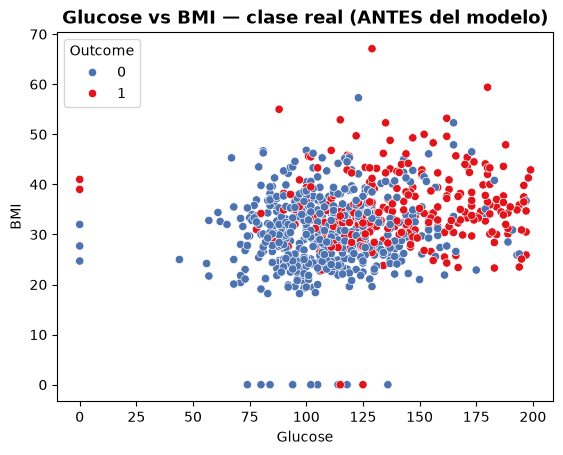

In [84]:
ax = sns.scatterplot(
    data=df,
    x = 'Glucose',
    y = 'BMI',
    hue= 'Outcome',
    palette= ["#4C72B0","#E1141B"],
    legend="full",
    )
ax.set_title("Glucose vs BMI — clase real (ANTES del modelo)", fontsize=13, fontweight="bold")

In [85]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


(768, 9)

In [86]:
total = len(df["Outcome"])
con=(df["Outcome"]==1).sum()
sin=len(df["Outcome"])-con
print(f"Hay {con} con diabetes y {sin} sin diabetes de {total} ")

Hay 268 con diabetes y 500 sin diabetes de 768 


Text(0.5, 1.0, 'Distribucion de Y')

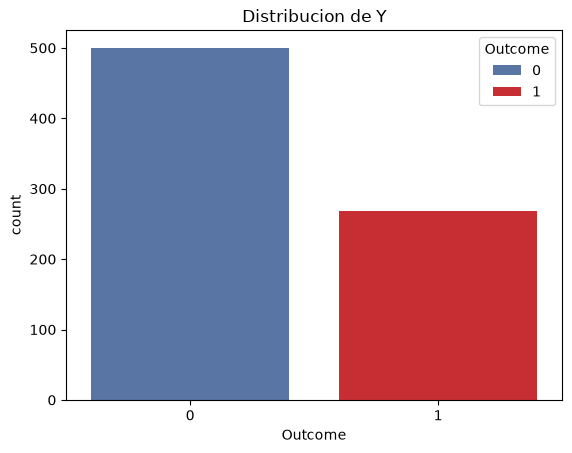

In [87]:
ax=sns.countplot(data=df,
              x="Outcome",
              hue="Outcome",
              palette= ["#4C72B0","#E1141B"] )
ax.set_title("Distribucion de Y")

In [88]:
#Columnas con ceros reales y objetivo
target ='Outcome'
zeros = 'Pregnancies'

In [89]:
y = df[target]
X = df.drop(columns=target)
#Test set plit
X_train,X_test,y_train,y_test = train_test_split(X,y,
                                                 test_size=0.2,
                                                 random_state=42,
                                                 stratify=y)

In [90]:
#Identificamos ceros y su distrbucion
df_nan = X.drop(columns=zeros).replace(0,np.nan).isna().sum().sort_values(ascending=False).to_frame(name="Nan Count")
df_nan["Percentaje"] = (df_nan["Nan Count"]/len(X)*100).round(2)
df_nan

,Nan Count,Percentaje
Insulin,374,48.70
SkinThickness,227,29.56
BloodPressure,35,4.56
BMI,11,1.43
Glucose,5,0.65
DiabetesPedigreeFunction,0,0.00
Age,0,0.00


In [91]:
#Previo a imputar eliminamos columnas con ceros reales
X_test_imp = X_test.drop(columns=zeros).replace(0,np.nan)
X_train_imp = X_train.drop(columns=zeros).replace(0,np.nan)

#Imputamos y reemplazamos ceros
imputer = KNNImputer(n_neighbors=5)
X_train_imp = imputer.fit_transform(X_train_imp)
X_test_imp = imputer.transform(X_test_imp)

#Agregamos nuevamente la columna con ceros reales
X_train_imp["Pregnancies"] = X_train["Pregnancies"]
X_test_imp["Pregnancies"] = X_test["Pregnancies"]


In [92]:
#Medir la simetria 
X_train_skew = X_train_imp.skew().sort_values(ascending = False).to_frame(name = "Skew")
X_train_skew

,Skew
Insulin,2.053459
DiabetesPedigreeFunction,1.818910
Age,1.128456
Pregnancies,0.886920
SkinThickness,0.736839
BMI,0.579661
Glucose,0.556871
BloodPressure,0.109741


In [93]:
scaler_dict = {
    "StandardScaler" : StandardScaler,
    "RobustScaler" : RobustScaler
    }

def scaler(skew):
    
        if -0.5 <= skew < 0.5:
            return "StandardScaler"
        elif 0.5<= skew <1 or -1 <= skew < -0.5:
            return "RobustScaler"
        elif 1<= skew <2 or -2 <= skew <-1:
            return "RobustScaler"
        elif skew >=2 or skew <-2:
            return "RobustScaler"

transformers = [
    (col, scaler_dict[scaler(skew)](), [col])
    for col, skew in X_train_imp.skew().items()
]

preprocesador = ColumnTransformer(transformers, verbose_feature_names_out=False)

X_train_scaled = preprocesador.fit_transform(X_train_imp)
X_test_scaled = preprocesador.transform(X_test_imp)


Entrenamiendo de modelos Logistic Regression, SVC y KNN

In [94]:
# Modelo LogisticRegression
LR = LogisticRegression(class_weight="balanced", random_state= 42)
LR.fit(X_train_scaled,y_train)

y_predict = LR.predict(X_test_scaled)
y_proba = LR.predict_proba(X_test_scaled)[:,1]

accuracy_LR = accuracy_score(y_test,y_predict)
f1_LR = f1_score(y_test,y_predict,average="binary",pos_label=1)
roc_LR = roc_auc_score(y_test,y_proba)
precision_LR = precision_score(y_test,y_predict)
recall_LR = recall_score(y_test,y_predict)

resultados_LR = pd.Series({"Accuracy" : accuracy_LR,
                           "F1" : f1_LR,
                           "ROC AUC" : roc_LR,
                           "Precision" : precision_LR,
                           "Recall" : recall_LR
                           }).to_frame(name="LogisticRegression")

# Modelo SCV

svc_model = CalibratedClassifierCV(
    SVC(class_weight = "balanced",
        random_state= 42),
    ensemble=False
)

svc_model.fit(X_train_scaled, y_train)

y_predict_SVC = svc_model.predict(X_test_scaled)
y_proba_SVC = svc_model.predict_proba(X_test_scaled)[:,1]

accuracy_SVC = accuracy_score(y_test, y_predict_SVC)
f1_SVC = f1_score(y_test,y_predict_SVC)
roc_SVC = roc_auc_score(y_test,y_proba_SVC)
precision_SVC = precision_score(y_test,y_predict_SVC)
recall_SVC = recall_score(y_test,y_predict_SVC)

resultados_LR["SVC"] = [accuracy_SVC,f1_SVC,roc_SVC,precision_SVC,recall_SVC]

# Modelo KNN

KNN = KNeighborsClassifier(n_neighbors=3)
KNN.fit(X_train_scaled,y_train)
y_predict_KNN=KNN.predict(X_test_scaled)
y_proba_KNN=KNN.predict_proba(X_test_scaled)[:,1]

accuracy_KNN = accuracy_score(y_test,y_predict_KNN)
f1_KNN = f1_score(y_test,y_predict_KNN)
roc_KNN = roc_auc_score(y_test,y_proba_KNN)
precision_KNN = precision_score(y_test,y_predict_KNN)
recall_KNN = recall_score(y_test,y_predict_KNN)

resultados_LR["KNN"] = [accuracy_KNN,f1_KNN,roc_KNN,precision_KNN,recall_KNN]

resultados_LR.sort_values(by="Recall", 
                          axis=1,
                          ascending=True)

,KNN,SVC,LogisticRegression
Accuracy,0.701299,0.746753,0.733766
F1,0.566038,0.621359,0.649573
ROC AUC,0.733704,0.809630,0.813704
Precision,0.576923,0.653061,0.603175
Recall,0.555556,0.592593,0.703704


In [95]:
best_accuracy = max(accuracy_KNN,accuracy_LR,accuracy_SVC)
best_f1 = max(f1_KNN,f1_LR,f1_SVC)
best_ROC = max(roc_KNN,roc_LR,roc_SVC)
best_presion = max(precision_KNN,precision_LR,precision_SVC)
best_recall = max(recall_KNN,recall_LR,recall_SVC)

In [96]:
print(f"Ajustandonos al contexto del modelo que es la deteccion de diabetes,\nse ha considerado a recall como indicador de referencia del modelo LogisticRegression \nes decir que sobre los pacientes que si tenian diabetes se predijo el {round((best_recall*100),2)}%")

Ajustandonos al contexto del modelo que es la deteccion de diabetes,
se ha considerado a recall como indicador de referencia del modelo LogisticRegression 
es decir que sobre los pacientes que si tenian diabetes se predijo el 70.37%


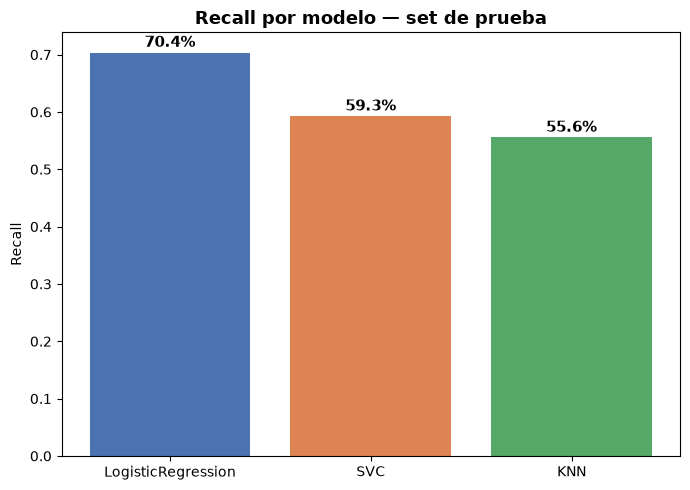

In [97]:
# Recall del split final (barras simples)
fig, ax = plt.subplots(figsize=(7,5))
nombres = ["LogisticRegression", "SVC", "KNN"]
valores = [recall_LR, recall_SVC, recall_KNN]
colores = ["#4C72B0", "#DD8452", "#55A868"]

bars = ax.bar(nombres, valores, color=colores)
for b, v in zip(bars, valores):
    ax.text(b.get_x()+b.get_width()/2, v+0.01, f"{v:.1%}", ha="center", fontsize=11, fontweight="bold")

ax.set_ylabel("Recall")
ax.set_title("Recall por modelo — set de prueba", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Expresion grafica de la distribucion de cada modelo

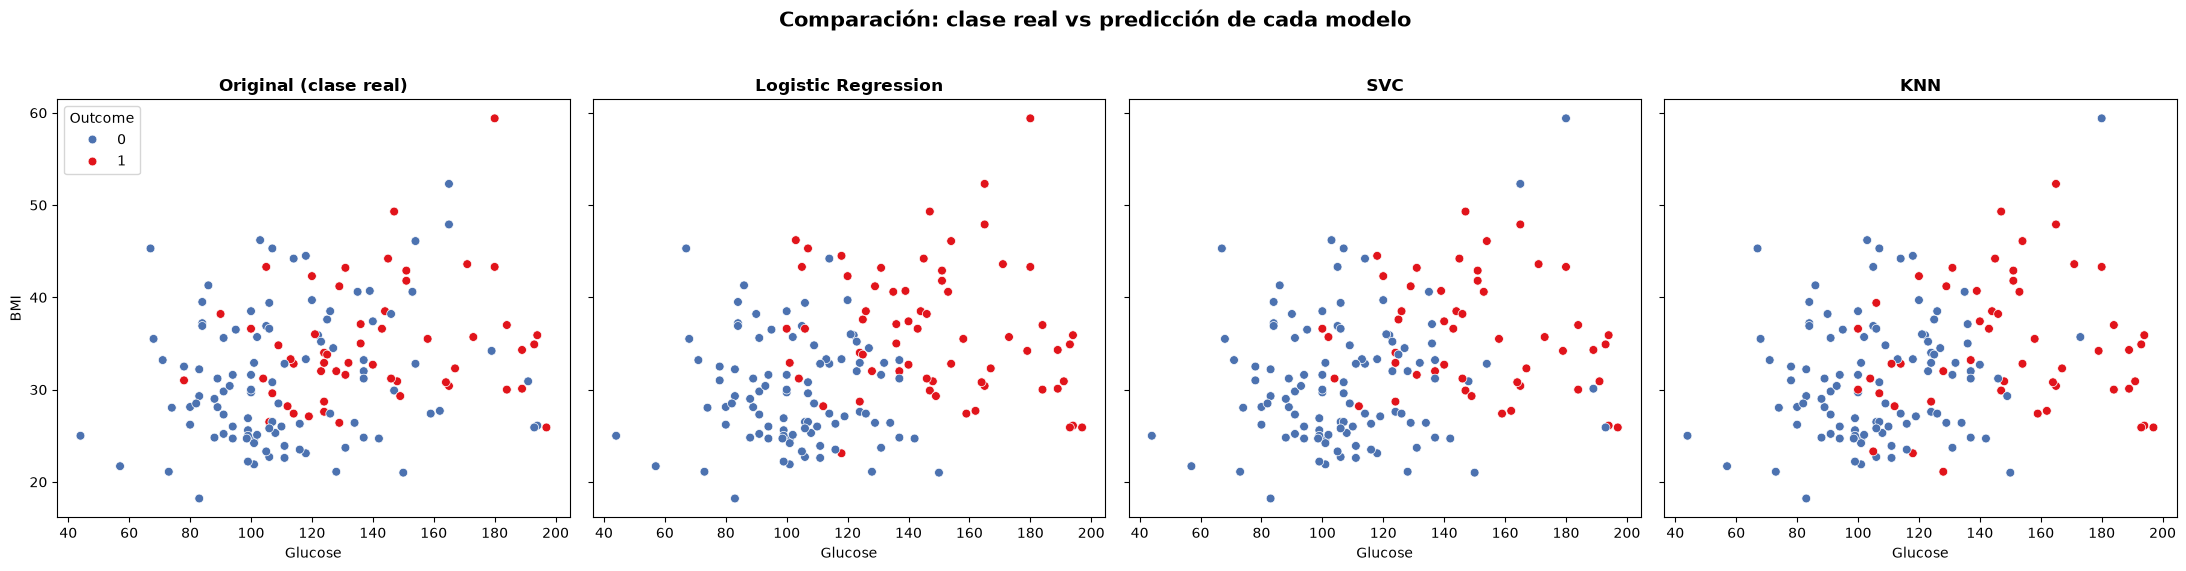

In [98]:
fig, axes = plt.subplots(1,4,figsize=(22,5.5), sharex= True, sharey=True)
palette = ["#4C72B0", "#E1141B"]

paneles = [("Original (clase real)", y_test.values),
           ("Logistic Regression", y_predict),
           ("SVC", y_predict_SVC),
           ("KNN", y_predict_KNN)]

for ax, (titulo, outcome_vals) in zip(axes, paneles):
    sns.scatterplot(data= X_test_imp.assign(Outcome = outcome_vals),
                    x= "Glucose", y="BMI", hue="Outcome",
                    palette=palette,legend="full" if ax is axes[0] else False, ax=ax, s=40
                    )
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel("Glucose")
    ax.set_ylabel("BMI" if ax is axes[0] else "")

fig.suptitle("Comparación: clase real vs predicción de cada modelo", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

Evaluacion de con CrossValidation

In [102]:
modelos = {
    "LogisticRegression" : LR,
    "SVC":svc_model,
    "KNN":KNN
}

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scores = {}
for nombre, modelo in modelos.items():
    pipeline = Pipeline([("preprocesador", preprocesador), ("modelo", modelo)])
    scores[nombre] = cross_val_score(pipeline, X_train_imp, y_train, cv=cv, scoring="recall")
    print(f"{nombre}: Recall CV = {scores[nombre].mean():.3f} (+/- {scores[nombre].std():.3f})")

LogisticRegression: Recall CV = 0.706 (+/- 0.040)
SVC: Recall CV = 0.603 (+/- 0.015)
KNN: Recall CV = 0.598 (+/- 0.059)


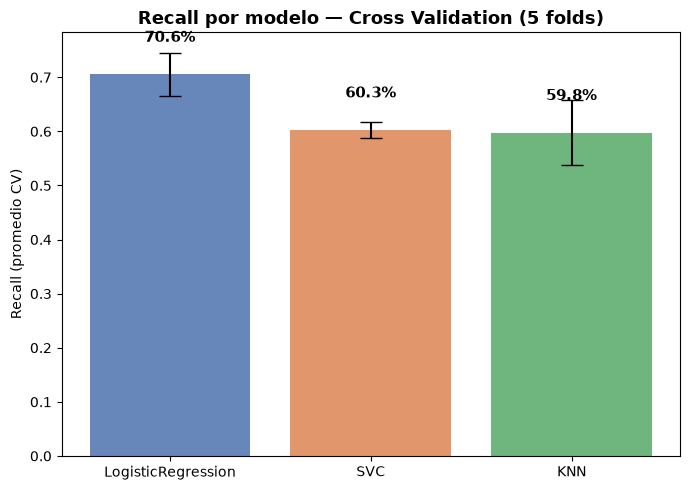

In [103]:
# Recall con Cross Validation (barras de error)
fig, ax = plt.subplots(figsize=(7,5))
medias = [scores["LogisticRegression"].mean(), scores["SVC"].mean(), scores["KNN"].mean()]
stds = [scores["LogisticRegression"].std(), scores["SVC"].std(), scores["KNN"].std()]

bars = ax.bar(nombres, medias, yerr=stds, capsize=8, color=colores, alpha=0.85)
for b, m in zip(bars, medias):
    ax.text(b.get_x()+b.get_width()/2, m+0.06, f"{m:.1%}", ha="center", fontsize=11, fontweight="bold")

ax.set_ylabel("Recall (promedio CV)")
ax.set_title("Recall por modelo — Cross Validation (5 folds)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [100]:
print("Ajustándonos al contexto del modelo (detección de diabetes), la validación cruzada de 5 folds "
      "\nconfirma que Logistic Regression es el modelo más consistente en Recall, con un promedio de "
      "\n70.6% (+/- 4.0%), muy similar al 70.4% obtenido en el set de prueba original. SVC (60.3% +/- 1.5%) "
      "\ny KNN (59.8% +/- 5.9%) se mantienen consistentemente por debajo en las 5 particiones. Esto confirma "
      "\nque la elección de Logistic Regression no depende de una partición particular de los datos, "
      "\nsino que es un resultado robusto y reproducible.")

Ajustándonos al contexto del modelo (detección de diabetes), la validación cruzada de 5 folds 
confirma que Logistic Regression es el modelo más consistente en Recall, con un promedio de 
70.6% (+/- 4.0%), muy similar al 70.4% obtenido en el set de prueba original. SVC (60.3% +/- 1.5%) 
y KNN (59.8% +/- 5.9%) se mantienen consistentemente por debajo en las 5 particiones. Esto confirma 
que la elección de Logistic Regression no depende de una partición particular de los datos, 
sino que es un resultado robusto y reproducible.
